In [7]:
input = {
    "function": "10 + x**2 - 10 * cos(2*pi*x)",
    "a": 0.75,
    "b": 2.75,
    "eps": 1e-3,
}

In [5]:
input = {
    "function": "x + sin(3.14159*x)",
    "a": 0.75,
    "b": 2.75,
    "eps": 1e-3,
}

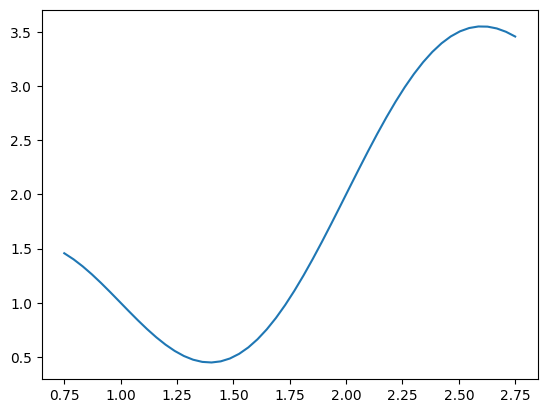

In [8]:
input = {
    "function": "x + sin(3.14159*x)",
    "a": 0.75,
    "b": 2.75,
    "eps": 1e-3,
}


def parse_function(f_str: str) -> Optional[sp.Function]:
  try:
    x = sp.Symbol('x')
    expr = sp.sympify(f_str)

    f = sp.lambdify(x, expr, 'numpy')
    return f
  except Exception as e:
    print(f"[ERROR]: Не удалось распарсить функцию, {e}")
    return None


def draw_func(f: sp.Function, a: float, b:float, num: int = 100):
  if a >= b:
    print("[WARNING]: Некорректные границы отрезка")
    return

  x_vals = np.linspace(a, b, num)
  y = f(x_vals)
  plt.plot(x_vals, y)
  plt.show()



f = parse_function(input["function"])
draw_func(f, input['a'], input['b'], 50)

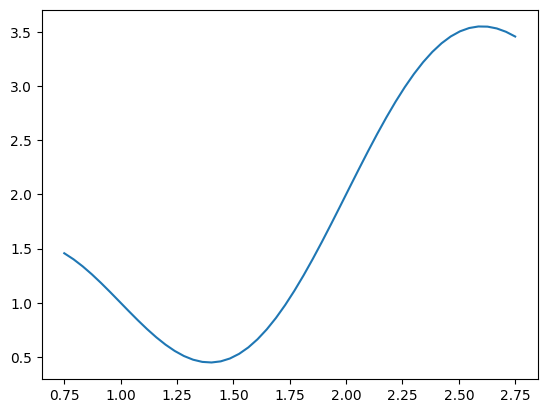

Вычисленная константа Липшица: 4.1415899096897135
РЕЗУЛЬТАТЫ РАСЧЕТОВ
Минимум (X, Y): [np.float64(1.3968779907421163), np.float64(0.4488992143649747)]
Число итераций: 9773
Затраченное время: 19.2709 сек


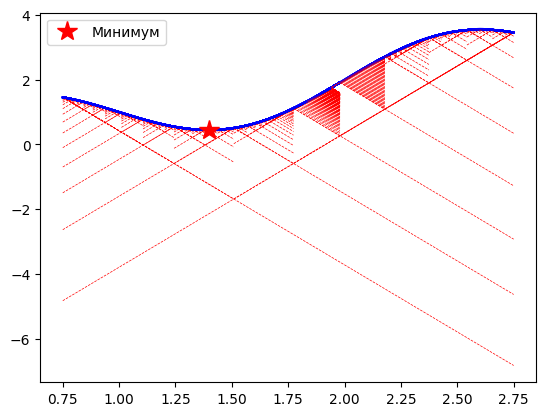

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
import time
from typing import Optional

from functools import wraps


def gather_stats(func):
    @wraps(func)
    def wrapper(*args, **kwargs):
        is_top_level = False
        if 'mins' not in kwargs or kwargs['mins'] is None:
            kwargs['mins'] = []
            is_top_level = True
        if 'stats' not in kwargs or kwargs['stats'] is None:
            kwargs['stats'] = {'iterations': 0}

        start_time = time.perf_counter() if is_top_level else 0

        func(*args, **kwargs)

        if is_top_level:
            total_time = time.perf_counter() - start_time
            mins = kwargs['mins']
            stats = kwargs['stats']

            local_min = min(mins, key=lambda x: x[1]) if mins else None

            print("="*40)
            print("РЕЗУЛЬТАТЫ РАСЧЕТОВ")
            print(f"Минимум (X, Y): {local_min}")
            print(f"Число итераций: {stats['iterations']}")
            print(f"Затраченное время: {total_time:.4f} сек")
            print("="*40)

            return stats['iterations'], total_time, local_min
    return wrapper


def parse_function(f_str: str) -> Optional[sp.Function]:
  try:
    x = sp.Symbol('x')
    expr = sp.sympify(f_str)

    f = sp.lambdify(x, expr, 'numpy')
    return f
  except Exception as e:
    print(f"[ERROR]: Не удалось распарсить функцию, {e}")
    return None


def draw_func(f: sp.Function, a: float, b:float, num: int = 100):
  if a >= b:
    print("[WARNING]: Некорректные границы отрезка")
    return

  x_vals = np.linspace(a, b, num)
  y = f(x_vals)
  plt.plot(x_vals, y)
  plt.show()


def find_L(f, a, b, eps=1e-6, num=10000) -> Optional[float]:
  x_vals = np.linspace(a, b, num)
  l = None
  diffs = np.abs((f(x_vals + eps) - f(x_vals))/ eps)
  return np.max(diffs)


def g(l: float, f: sp.Function, x: np.array, u: float):
  return f(u) - l * np.abs(x - u)


@gather_stats
def draw_extra(l: float, a: float, b: float, f: sp.Function, eps: float = 1e-2, nums: int = 50, mins: list = None, stats: dict = None):
    if abs(b - a) < 1e-4:
        local_min = a if f(a) <= f(b) else b
        mins.append([local_min, f(local_min)])
        return

    stats['iterations'] += 1

    x_vals = np.linspace(a, b, nums)

    g0 = g(l, f, x_vals, u=a)
    g1 = g(l, f, x_vals, u=b)

    plt.plot(x_vals, f(x_vals), color='blue', alpha=0.3)
    plt.plot(x_vals, g0, color='red', linestyle='--', linewidth=0.5)
    plt.plot(x_vals, g1, color='red', linestyle='--', linewidth=0.5)

    u = (f(a) - f(b) + l*(a + b)) / (2 * l)

    if f(u) - (f(a) + f(b) - l*(b - a)) / 2 < eps:
        mins.append([u, f(u)])
        return

    draw_extra(l, a, u, f, eps=eps, nums=nums, mins=mins, stats=stats)
    draw_extra(l, u, b, f, eps=eps, nums=nums, mins=mins, stats=stats)


def main():
    f = parse_function(input["function"])
    if f is None:
        return

    draw_func(f, input['a'], input['b'], 50)

    l = find_L(f, input['a'], input['b'])
    print(f"Вычисленная константа Липшица: {l}")

    iterations, total_time, local_min = draw_extra(l, input['a'], input['b'], f, eps=input['eps'])

    if local_min:
        l_min_x, l_min_y = local_min
        plt.plot(l_min_x, l_min_y, 'r*', markersize=15, label="Минимум")
        plt.legend()

    plt.show()

main()
